# 07 · Are the models right, and is the automation worth using?
High scores on one split are not enough. This notebook repeats the tests across many splits, checks stability, and measures the practical gain from automating lead follow-up and target setting.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold,RepeatedKFold,cross_validate,KFold,cross_val_predict
from sklearn.pipeline import Pipeline,make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.linear_model import LogisticRegression,LinearRegression
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor
from sklearn.dummy import DummyClassifier,DummyRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from mlxtend.frequent_patterns import apriori,association_rules
SEED=42; c=pd.read_csv('../Dataset/customers.csv'); out=[]
def add(task,test,model,metric,mean,sd=None,note=''): out.append(dict(Task=task,Test=test,Model=model,Metric=metric,Mean=round(float(mean),4),SD=None if sd is None else round(float(sd),4),Note=note))

## Classification and regression: 5-fold cross-validation repeated 3 times

In [2]:
y=(c.Conversion_Segment=='High').astype(int)
catf=['Survey_Channel','A5_Area','A8_Occupation','B3_Primary_Channel','B4_Used_Group_Buying_Before','B5_In_Community_WhatsApp_Buying_Group','E2_Most_Important_Feature','F4_Preferred_Payment']
numf=['A2_Age','A6_Household_Size','A7_Monthly_Income_AED','A9_SME_Employees','Is_SME','B1_Monthly_Spend_Eligible_AED','B2_Online_Orders_Per_Month','B6_Max_Delivery_Fee_AED','F1_Min_Discount_To_Switch_Pct','F2_Max_Wait_Days','F3_Membership_WTP_AED_Month']+[x for x in c.columns if x[:2] in('C1','C2','C3','C4','C5','C6','C7','C8') or x.startswith(('CAT_','FEAT_'))]
pre=ColumnTransformer([('n',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),numf),('c',make_pipeline(SimpleImputer(strategy='constant',fill_value='Missing'),OneHotEncoder(handle_unknown='ignore')),catf)])
cv=RepeatedStratifiedKFold(n_splits=5,n_repeats=3,random_state=SEED); X=c[numf+catf]
ms={'Baseline':DummyClassifier(strategy='most_frequent'),'Logistic Regression':LogisticRegression(max_iter=2000,class_weight='balanced'),'Random Forest':RandomForestClassifier(200,min_samples_leaf=5,class_weight='balanced',random_state=SEED,n_jobs=-1)}
for n,m in ms.items():
    r=cross_validate(Pipeline([('p',pre),('m',m)]),X,y,cv=cv,scoring=['f1','roc_auc','recall','precision','accuracy'])
    for k in ['f1','roc_auc','recall','precision','accuracy']: add('Classification','Repeated 5-fold CV',n,k,r['test_'+k].mean(),r['test_'+k].std())
rf=Pipeline([('p',pre),('m',ms['Random Forest'])])
sh=cross_validate(rf,X,np.random.default_rng(SEED).permutation(y.values),cv=RepeatedStratifiedKFold(n_splits=5,n_repeats=1,random_state=SEED),scoring='roc_auc')['test_score']; add('Classification','Shuffled labels (should be near 0.5)','Random Forest','roc_auc',sh.mean(),sh.std())
yr=c.G4_Expected_Order_Value_AED; cr=['A8_Occupation','B3_Primary_Channel','B4_Used_Group_Buying_Before']
nr=['Is_SME','A9_SME_Employees','A2_Age','A6_Household_Size','A7_Monthly_Income_AED','B1_Monthly_Spend_Eligible_AED','B2_Online_Orders_Per_Month','B6_Max_Delivery_Fee_AED','C1_Price_Consciousness','C2_Willing_To_Wait_For_Deal','C3_Trust_New_Platforms','C7_Values_Price_Transparency','F1_Min_Discount_To_Switch_Pct','F2_Max_Wait_Days']
pr=ColumnTransformer([('n',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),nr),('c',OneHotEncoder(handle_unknown='ignore'),cr)]); Xr=c[nr+cr]
rm={'Baseline':DummyRegressor(),'Linear Regression':LinearRegression(),'Random Forest':RandomForestRegressor(200,min_samples_leaf=3,random_state=SEED,n_jobs=-1)}
for n,m in rm.items():
    r=cross_validate(Pipeline([('p',pr),('m',m)]),Xr,yr,cv=RepeatedKFold(n_splits=5,n_repeats=3,random_state=SEED),scoring=['r2','neg_mean_absolute_error'])
    add('Regression','Repeated 5-fold CV',n,'R2',r['test_r2'].mean(),r['test_r2'].std()); add('Regression','Repeated 5-fold CV',n,'MAE_AED',-r['test_neg_mean_absolute_error'].mean(),r['test_neg_mean_absolute_error'].std())

/usr/local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/site-packages/sklearn/metrics/_clas

/usr/local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/site-packages/sklearn/metrics/_clas

/usr/local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/site-packages/sklearn/metrics/_clas

## Clustering and Apriori: are the patterns stable?

In [3]:
FEATS=['A7_Monthly_Income_AED','A6_Household_Size','B1_Monthly_Spend_Eligible_AED','B2_Online_Orders_Per_Month','B6_Max_Delivery_Fee_AED','C1_Price_Consciousness','C2_Willing_To_Wait_For_Deal','C3_Trust_New_Platforms','C4_Social_Influence','C5_Convenience_Priority','C7_Values_Price_Transparency','F1_Min_Discount_To_Switch_Pct','F2_Max_Wait_Days']
Z0=c[FEATS].copy()
for col in ['A7_Monthly_Income_AED','B1_Monthly_Spend_Eligible_AED']: Z0[col]=np.log1p(Z0[col])
Z=make_pipeline(SimpleImputer(strategy='median'),StandardScaler()).fit_transform(Z0); ref=KMeans(5,n_init=20,random_state=SEED).fit_predict(Z); rng=np.random.default_rng(SEED); a=[]
for i in range(30):
    idx=rng.choice(len(Z),int(.8*len(Z)),replace=False); a.append(adjusted_rand_score(ref,KMeans(5,n_init=10,random_state=i).fit(Z[idx]).predict(Z)))
add('Clustering','Refit on 30 random 80% samples','K-Means k=5','Adjusted Rand Index',np.mean(a),np.std(a),'1 = same segments; 0 = random')
b=c.filter(like='CAT_').astype(bool); perm=np.random.default_rng(SEED).permutation(len(b)); h=[b.iloc[perm[:600]],b.iloc[perm[600:]]]; R=[]
for x in h:
    r=association_rules(apriori(x,min_support=.08,use_colnames=True),num_itemsets=len(x),metric='confidence',min_threshold=.4); r=r[r.lift>1.05]; R.append(r.assign(k=r.antecedents.map(lambda s:'+'.join(sorted(s)))+'>'+r.consequents.map(lambda s:'+'.join(sorted(s)))).set_index('k').lift)
both=R[0].index.intersection(R[1].index); add('Association','Split-half: rules found in both halves','Apriori','Share of half-A rules',len(both)/len(R[0]),None,f'{len(R[0])} and {len(R[1])} rules; {len(both)} shared'); add('Association','Split-half: lift agreement','Apriori','Correlation of lift',R[0][both].corr(R[1][both]))

## Is the automation useful?

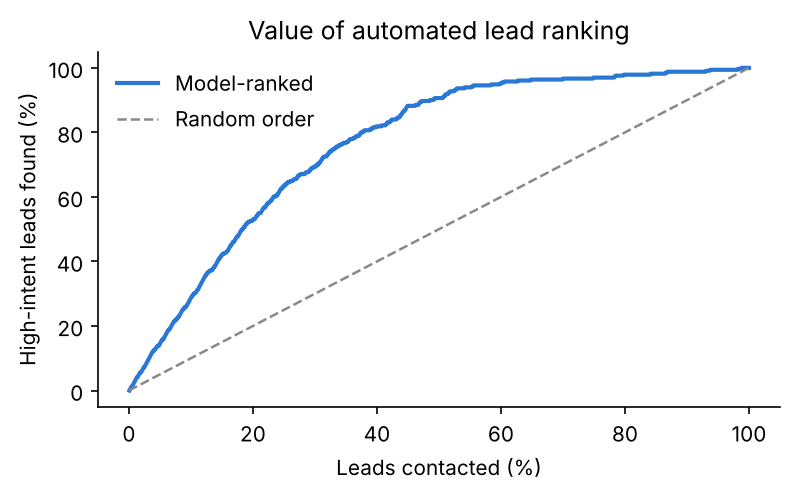

              Task                                                 Test                Model                      Metric      Mean       SD                                                      Note
0   Classification                                   Repeated 5-fold CV             Baseline                          f1    0.0000   0.0000                                                          
1   Classification                                   Repeated 5-fold CV             Baseline                     roc_auc    0.5000   0.0000                                                          
2   Classification                                   Repeated 5-fold CV             Baseline                      recall    0.0000   0.0000                                                          
3   Classification                                   Repeated 5-fold CV             Baseline                   precision    0.0000   0.0000                                                          
4   Classi

In [4]:
L=pd.read_csv('../Results/Lead_Scores.csv').sort_values('Lead_Score',ascending=False).reset_index(drop=True); T=L.Actual_High_Intent.sum(); N=len(L)
g=pd.DataFrame({'Share_Contacted':(np.arange(N)+1)/N,'Scored':L.Actual_High_Intent.cumsum()/T}); g['Random']=g.Share_Contacted; g.iloc[::5].round(4).to_csv('../Results/Lead_Gain.csv',index=False)
for s in [.1,.2,.3,.4,.5]:
    n=int(N*s); hit=L.Actual_High_Intent.iloc[:n].sum(); add('Automation',f'Contact top {int(s*100)}% ({n} leads)','Lead score','Share of high-intent found',hit/T,None,f'{hit} of {T}; precision {hit/n:.3f}; random would find about {T*s:.0f}')
fig,ax=plt.subplots(figsize=(5.4,3.4),dpi=150); ax.plot(g.Share_Contacted*100,g.Scored*100,color='#2a78d6',lw=2,label='Model-ranked'); ax.plot([0,100],[0,100],color='#8a8984',lw=1.2,ls='--',label='Random order'); ax.set(xlabel='Leads contacted (%)',ylabel='High-intent leads found (%)',title='Value of automated lead ranking'); ax.spines[['top','right']].set_visible(False); ax.legend(frameon=False); plt.tight_layout(); plt.savefig('../Results/figures/eda/10_lead_gain.png'); plt.show()
oof=cross_val_predict(Pipeline([('p',pr),('m',rm['Random Forest'])]),Xr,yr,cv=KFold(5,shuffle=True,random_state=SEED)); rg=np.random.default_rng(SEED); e1=[];e2=[]
for _ in range(1000):
    i=rg.choice(N,40,replace=False); ac=yr.iloc[i].sum(); e1.append(abs(oof[i].sum()-ac)/ac); e2.append(abs(yr.mean()*40-ac)/ac)
add('Automation','Forecast of 40-buyer campaign value (1,000 samples)','Random Forest','Median absolute % error',np.median(e1)); add('Automation','Forecast of 40-buyer campaign value (1,000 samples)','Average order value','Median absolute % error',np.median(e2))
v=pd.DataFrame(out); v.to_csv('../Results/Model_Validation.csv',index=False); print(v.to_string())